In [1]:
# NaaVRE step 1: Read Input Rows
# Purpose: Read the raw CSV file into a list of dictionaries

import csv
from pathlib import Path

input_path = Path("C:/Users/alex/Downloads/NaaVRE-extension/NaaVRE-extension/naavre-ai-assistant/labs/energy/data/building_energy.csv")

if not input_path.is_file():
    raise FileNotFoundError(f"Input file not found: {input_path}")

expected_headers = ["reading_date", "building_id", "electricity_kwh"]

with input_path.open("r", encoding="utf-8-sig", newline="") as f:
    reader = csv.DictReader(f)
    if reader.fieldnames is None:
        raise ValueError("Input CSV has no header row.")
    if reader.fieldnames != expected_headers:
        raise ValueError(f"Unexpected CSV headers: {reader.fieldnames}. Expected: {expected_headers}")
    raw_records = list(reader)

print(f"Read {len(raw_records)} raw records from {input_path.name}")

Read 28 raw records from building_energy.csv


In [2]:
# NaaVRE step 2: Assess Data Quality
# Purpose: Validate dates, values, and keys; separate valid, missing, and rejected records

import math
from datetime import date

valid_records = []
missing_records = []
rejected_records = []

seen_keys = set()
rejection_reasons = []

for record in raw_records:
    reading_date_raw = record.get("reading_date", "").strip()
    building_id_raw = record.get("building_id", "").strip()
    electricity_raw = record.get("electricity_kwh", "").strip()

    # Check for duplicate observation key
    key = (reading_date_raw, building_id_raw)
    if key in seen_keys:
        rejection_reasons.append(f"Duplicate key: {key}")
        rejected_records.append(record)
        continue
    seen_keys.add(key)

    # Validate date
    try:
        parsed_date = date.fromisoformat(reading_date_raw)
    except (ValueError, TypeError):
        rejection_reasons.append(f"Invalid date: {reading_date_raw}")
        rejected_records.append(record)
        continue

    # Validate building_id
    if not building_id_raw:
        rejection_reasons.append("Missing building_id")
        rejected_records.append(record)
        continue

    # Handle missing electricity value
    if electricity_raw == "":
        missing_records.append(record)
        continue

    # Validate numeric value
    try:
        value = float(electricity_raw)
    except (ValueError, TypeError):
        rejection_reasons.append(f"Non-numeric electricity_kwh: {electricity_raw}")
        rejected_records.append(record)
        continue

    if math.isnan(value) or math.isinf(value):
        rejection_reasons.append(f"Non-finite electricity_kwh: {electricity_raw}")
        rejected_records.append(record)
        continue

    if value < 0:
        rejection_reasons.append(f"Negative electricity_kwh: {electricity_raw}")
        rejected_records.append(record)
        continue

    # Valid record
    valid_record = {
        "reading_date": reading_date_raw,
        "building_id": building_id_raw,
        "electricity_kwh": value
    }
    valid_records.append(valid_record)

# Build validation report
buildings = sorted(set(r["building_id"] for r in raw_records if r.get("building_id", "").strip()))

per_building_stats = {}
for b in buildings:
    b_valid = [r for r in valid_records if r["building_id"] == b]
    b_missing = [r for r in missing_records if r.get("building_id", "").strip() == b]
    b_rejected = [r for r in rejected_records if r.get("building_id", "").strip() == b]
    per_building_stats[b] = {
        "valid": len(b_valid),
        "missing": len(b_missing),
        "rejected": len(b_rejected)
    }

validation_report = {
    "total_raw_records": len(raw_records),
    "valid_count": len(valid_records),
    "missing_count": len(missing_records),
    "rejected_count": len(rejected_records),
    "per_building": per_building_stats,
    "rejection_reasons": rejection_reasons
}

print("Validation Report:")
print(f"  Total raw records: {validation_report['total_raw_records']}")
print(f"  Valid: {validation_report['valid_count']}")
print(f"  Missing: {validation_report['missing_count']}")
print(f"  Rejected: {validation_report['rejected_count']}")
for b, stats in per_building_stats.items():
    print(f"  Building {b}: valid={stats['valid']}, missing={stats['missing']}, rejected={stats['rejected']}")
if rejection_reasons:
    print("  Rejection reasons:")
    for reason in rejection_reasons:
        print(f"    - {reason}")

Validation Report:
  Total raw records: 28
  Valid: 27
  Missing: 1
  Rejected: 0
  Building A: valid=14, missing=0, rejected=0
  Building B: valid=13, missing=1, rejected=0


In [3]:
# NaaVRE step 3: Flag High Readings
# Purpose: Identify valid readings >= 40 kWh and mark them for review

HIGH_READING_THRESHOLD_KWH = 40.0

flagged_records = []
for record in valid_records:
    if record["electricity_kwh"] >= HIGH_READING_THRESHOLD_KWH:
        flagged_record = dict(record)
        flagged_record["flagged_high"] = True
        flagged_records.append(flagged_record)

print(f"Flagged {len(flagged_records)} valid reading(s) >= {HIGH_READING_THRESHOLD_KWH} kWh for review.")
for fr in flagged_records:
    print(f"  {fr['reading_date']} | Building {fr['building_id']} | {fr['electricity_kwh']} kWh")

Flagged 1 valid reading(s) >= 40.0 kWh for review.
  2026-01-10 | Building B | 80.0 kWh


In [4]:
# NaaVRE step 4: Compute Summaries
# Purpose: Calculate per-building statistics and same-date overlap comparisons

import statistics

# --- Per-building summaries ---
buildings = sorted(set(r["building_id"] for r in valid_records))

building_summaries = {}
for b in buildings:
    b_values = [r["electricity_kwh"] for r in valid_records if r["building_id"] == b]
    count = len(b_values)
    total = sum(b_values)
    mean = statistics.mean(b_values) if count > 0 else None
    building_summaries[b] = {
        "building_id": b,
        "available_readings": count,
        "total_kwh": total,
        "mean_kwh": mean
    }

# --- Same-date overlap comparison ---
# Build a mapping: date -> {building_id: value}
date_map = {}
for r in valid_records:
    d = r["reading_date"]
    b = r["building_id"]
    if d not in date_map:
        date_map[d] = {}
    date_map[d][b] = r["electricity_kwh"]

# Find dates where both buildings have a valid reading
overlap_dates = sorted([d for d, bm in date_map.items() if len(bm) == len(buildings)])

overlap_comparison = []
for d in overlap_dates:
    row = {"reading_date": d}
    for b in buildings:
        row[f"building_{b}_kwh"] = date_map[d][b]
    # Compute difference (A - B) if both are A and B
    if "A" in buildings and "B" in buildings:
        row["difference_kwh"] = date_map[d]["A"] - date_map[d]["B"]
    overlap_comparison.append(row)

overlap_count = len(overlap_dates)

# --- Print summaries ---
print("Per-Building Summaries (full 14-day window):")
print("-" * 50)
for b in buildings:
    s = building_summaries[b]
    print(f"Building {b}:")
    print(f"  Available readings: {s['available_readings']}")
    print(f"  Total kWh: {s['total_kwh']:.2f}")
    if s["mean_kwh"] is not None:
        print(f"  Mean kWh: {s['mean_kwh']:.2f}")
    else:
        print(f"  Mean kWh: N/A (no valid readings)")
    print()

print(f"Same-Date Overlap Comparison: {overlap_count} date(s) with valid readings from both buildings")
print("-" * 50)
if overlap_comparison:
    for row in overlap_comparison:
        parts = [f"{row['reading_date']}"]
        for b in buildings:
            parts.append(f"Bldg {b}: {row[f'building_{b}_kwh']:.2f} kWh")
        if "difference_kwh" in row:
            parts.append(f"Diff (A-B): {row['difference_kwh']:+.2f} kWh")
        print("  " + " | ".join(parts))
else:
    print("  No overlapping dates with valid readings from both buildings.")

print()
print("Note: Full-period sums are incomplete where days are missing.")
print("Note: No efficiency or causal claims are made; floor area, occupancy, and weather are not supplied.")

Per-Building Summaries (full 14-day window):
--------------------------------------------------
Building A:
  Available readings: 14
  Total kWh: 301.00
  Mean kWh: 21.50

Building B:
  Available readings: 13
  Total kWh: 395.00
  Mean kWh: 30.38

Same-Date Overlap Comparison: 13 date(s) with valid readings from both buildings
--------------------------------------------------
  2026-01-01 | Bldg A: 20.00 kWh | Bldg B: 25.00 kWh | Diff (A-B): -5.00 kWh
  2026-01-02 | Bldg A: 21.00 kWh | Bldg B: 26.00 kWh | Diff (A-B): -5.00 kWh
  2026-01-03 | Bldg A: 15.00 kWh | Bldg B: 18.00 kWh | Diff (A-B): -3.00 kWh
  2026-01-04 | Bldg A: 14.00 kWh | Bldg B: 17.00 kWh | Diff (A-B): -3.00 kWh
  2026-01-05 | Bldg A: 23.00 kWh | Bldg B: 28.00 kWh | Diff (A-B): -5.00 kWh
  2026-01-06 | Bldg A: 24.00 kWh | Bldg B: 29.00 kWh | Diff (A-B): -5.00 kWh
  2026-01-08 | Bldg A: 26.00 kWh | Bldg B: 31.00 kWh | Diff (A-B): -5.00 kWh
  2026-01-09 | Bldg A: 27.00 kWh | Bldg B: 32.00 kWh | Diff (A-B): -5.00 kWh
  20

SVG chart saved to: outputs\energy_chart.svg


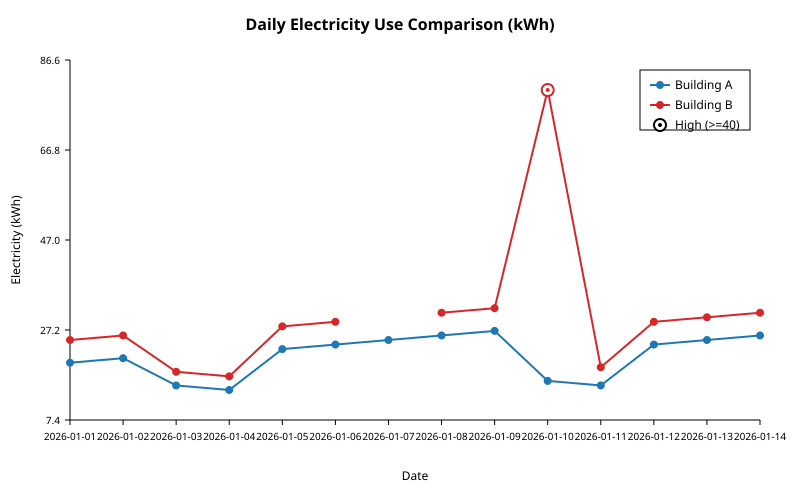

In [5]:
# NaaVRE step 5: Generate Visualization
# Purpose: Create an SVG line chart showing daily trends, gaps for missing data, and marked high readings

import xml.etree.ElementTree as ET
from datetime import date
from pathlib import Path

# --- Configuration ---
SVG_WIDTH = 800
SVG_HEIGHT = 500
MARGIN = {"top": 60, "right": 40, "bottom": 80, "left": 70}
PLOT_WIDTH = SVG_WIDTH - MARGIN["left"] - MARGIN["right"]
PLOT_HEIGHT = SVG_HEIGHT - MARGIN["top"] - MARGIN["bottom"]

# Colors for buildings
BUILDING_COLORS = {
    "A": "#1f77b4",  # Blue
    "B": "#d62728"   # Red
}

# --- Prepare Data ---
# Get all unique dates from valid records and missing records to define the x-axis range
all_dates = set()
for r in valid_records:
    all_dates.add(r["reading_date"])
for r in missing_records:
    all_dates.add(r["reading_date"])

if not all_dates:
    raise ValueError("No dates found in valid or missing records to plot.")

sorted_dates = sorted(all_dates)
n_dates = len(sorted_dates)

# Get all unique buildings
buildings = sorted(set(r["building_id"] for r in valid_records))
if not buildings:
    raise ValueError("No buildings found in valid records to plot.")

# Determine Y-axis range
all_values = [r["electricity_kwh"] for r in valid_records]
if not all_values:
    raise ValueError("No valid readings to plot.")

y_min = min(all_values)
y_max = max(all_values)

# Add some padding to y-axis
y_range = y_max - y_min
if y_range == 0:
    y_range = 1.0  # Avoid division by zero
y_min_plot = y_min - 0.1 * y_range
y_max_plot = y_max + 0.1 * y_range
y_range_plot = y_max_plot - y_min_plot

# --- Helper Functions ---
def date_to_x(date_str):
    """Convert a date string to an x-coordinate."""
    # Find index in sorted_dates
    try:
        idx = sorted_dates.index(date_str)
    except ValueError:
        # If date not in list (shouldn't happen), interpolate or return 0
        return MARGIN["left"]
    
    if n_dates == 1:
        return MARGIN["left"] + PLOT_WIDTH / 2
    return MARGIN["left"] + (idx / (n_dates - 1)) * PLOT_WIDTH

def value_to_y(value):
    """Convert a kWh value to a y-coordinate."""
    if y_range_plot == 0:
        return MARGIN["top"] + PLOT_HEIGHT / 2
    return MARGIN["top"] + PLOT_HEIGHT - ((value - y_min_plot) / y_range_plot) * PLOT_HEIGHT

# --- Build SVG ---
svg = ET.Element("svg", {
    "width": str(SVG_WIDTH),
    "height": str(SVG_HEIGHT),
    "xmlns": "http://www.w3.org/2000/svg"
})

# Background
bg = ET.SubElement(svg, "rect", {
    "width": str(SVG_WIDTH),
    "height": str(SVG_HEIGHT),
    "fill": "white"
})

# Title
title = ET.SubElement(svg, "text", {
    "x": str(SVG_WIDTH / 2),
    "y": "30",
    "text-anchor": "middle",
    "font-size": "16",
    "font-family": "sans-serif",
    "font-weight": "bold"
})
title.text = "Daily Electricity Use Comparison (kWh)"

# --- Axes ---
# X-axis line
ET.SubElement(svg, "line", {
    "x1": str(MARGIN["left"]),
    "y1": str(MARGIN["top"] + PLOT_HEIGHT),
    "x2": str(MARGIN["left"] + PLOT_WIDTH),
    "y2": str(MARGIN["top"] + PLOT_HEIGHT),
    "stroke": "black",
    "stroke-width": "1"
})

# Y-axis line
ET.SubElement(svg, "line", {
    "x1": str(MARGIN["left"]),
    "y1": str(MARGIN["top"]),
    "x2": str(MARGIN["left"]),
    "y2": str(MARGIN["top"] + PLOT_HEIGHT),
    "stroke": "black",
    "stroke-width": "1"
})

# X-axis labels (dates)
# Show every date if few, otherwise every other or so
label_step = max(1, n_dates // 10)
for i, d in enumerate(sorted_dates):
    if i % label_step == 0 or i == n_dates - 1:
        x = date_to_x(d)
        # Tick mark
        ET.SubElement(svg, "line", {
            "x1": str(x),
            "y1": str(MARGIN["top"] + PLOT_HEIGHT),
            "x2": str(x),
            "y2": str(MARGIN["top"] + PLOT_HEIGHT + 5),
            "stroke": "black",
            "stroke-width": "1"
        })
        # Label
        label = ET.SubElement(svg, "text", {
            "x": str(x),
            "y": str(MARGIN["top"] + PLOT_HEIGHT + 20),
            "text-anchor": "middle",
            "font-size": "10",
            "font-family": "sans-serif"
        })
        label.text = d

# Y-axis labels (values)
num_y_ticks = 5
for i in range(num_y_ticks):
    val = y_min_plot + (i / (num_y_ticks - 1)) * y_range_plot
    y = value_to_y(val)
    # Tick mark
    ET.SubElement(svg, "line", {
        "x1": str(MARGIN["left"] - 5),
        "y1": str(y),
        "x2": str(MARGIN["left"]),
        "y2": str(y),
        "stroke": "black",
        "stroke-width": "1"
    })
    # Label
    label = ET.SubElement(svg, "text", {
        "x": str(MARGIN["left"] - 10),
        "y": str(y + 4),
        "text-anchor": "end",
        "font-size": "10",
        "font-family": "sans-serif"
    })
    label.text = f"{val:.1f}"

# Axis Titles
x_title = ET.SubElement(svg, "text", {
    "x": str(MARGIN["left"] + PLOT_WIDTH / 2),
    "y": str(SVG_HEIGHT - 20),
    "text-anchor": "middle",
    "font-size": "12",
    "font-family": "sans-serif"
})
x_title.text = "Date"

y_title = ET.SubElement(svg, "text", {
    "x": "20",
    "y": str(MARGIN["top"] + PLOT_HEIGHT / 2),
    "text-anchor": "middle",
    "font-size": "12",
    "font-family": "sans-serif",
    "transform": f"rotate(-90, 20, {MARGIN['top'] + PLOT_HEIGHT / 2})"
})
y_title.text = "Electricity (kWh)"

# --- Plot Lines ---
# For each building, draw line segments between consecutive valid points
# If a point is missing, the line breaks (gap)

for b in buildings:
    color = BUILDING_COLORS.get(b, "#000000")
    
    # Get valid points for this building, sorted by date
    b_points = [r for r in valid_records if r["building_id"] == b]
    b_points.sort(key=lambda x: x["reading_date"])
    
    # Draw line segments
    for i in range(len(b_points) - 1):
        p1 = b_points[i]
        p2 = b_points[i + 1]
        
        # Check if dates are consecutive in the full date list
        # If there's a missing date between them, we still draw a line? 
        # Protocol says: "Show a gap at a missing reading, rather than a zero or a continuous interpolated line."
        # This implies we should NOT connect points across a missing date.
        
        # Find indices in sorted_dates
        idx1 = sorted_dates.index(p1["reading_date"])
        idx2 = sorted_dates.index(p2["reading_date"])
        
        # If they are not consecutive in the sorted_dates list, there is a gap
        if idx2 - idx1 > 1:
            continue  # Skip drawing line across gap
        
        x1 = date_to_x(p1["reading_date"])
        y1 = value_to_y(p1["electricity_kwh"])
        x2 = date_to_x(p2["reading_date"])
        y2 = value_to_y(p2["electricity_kwh"])
        
        ET.SubElement(svg, "line", {
            "x1": str(x1),
            "y1": str(y1),
            "x2": str(x2),
            "y2": str(y2),
            "stroke": color,
            "stroke-width": "2"
        })
    
    # Draw points
    for p in b_points:
        x = date_to_x(p["reading_date"])
        y = value_to_y(p["electricity_kwh"])
        
        # Check if this point is flagged as high
        is_flagged = any(
            fr["reading_date"] == p["reading_date"] and 
            fr["building_id"] == p["building_id"] 
            for fr in flagged_records
        )
        
        if is_flagged:
            # Draw a distinct symbol for high readings (e.g., a star or larger circle with different fill)
            # Let's use a larger circle with a white center and colored border
            ET.SubElement(svg, "circle", {
                "cx": str(x),
                "cy": str(y),
                "r": "6",
                "fill": "white",
                "stroke": color,
                "stroke-width": "2"
            })
            # Add a small dot in the center
            ET.SubElement(svg, "circle", {
                "cx": str(x),
                "cy": str(y),
                "r": "2",
                "fill": color
            })
        else:
            # Normal point
            ET.SubElement(svg, "circle", {
                "cx": str(x),
                "cy": str(y),
                "r": "4",
                "fill": color
            })

# --- Legend ---
legend_x = MARGIN["left"] + PLOT_WIDTH - 120
legend_y = MARGIN["top"] + 10

# Legend box
ET.SubElement(svg, "rect", {
    "x": str(legend_x),
    "y": str(legend_y),
    "width": "110",
    "height": "60",
    "fill": "white",
    "stroke": "black",
    "stroke-width": "1"
})

for i, b in enumerate(buildings):
    color = BUILDING_COLORS.get(b, "#000000")
    ly = legend_y + 15 + i * 20
    
    # Line sample
    ET.SubElement(svg, "line", {
        "x1": str(legend_x + 10),
        "y1": str(ly),
        "x2": str(legend_x + 30),
        "y2": str(ly),
        "stroke": color,
        "stroke-width": "2"
    })
    
    # Point sample
    ET.SubElement(svg, "circle", {
        "cx": str(legend_x + 20),
        "cy": str(ly),
        "r": "4",
        "fill": color
    })
    
    # Label
    label = ET.SubElement(svg, "text", {
        "x": str(legend_x + 35),
        "y": str(ly + 4),
        "font-size": "12",
        "font-family": "sans-serif"
    })
    label.text = f"Building {b}"

# Legend for high readings
ly_high = legend_y + 15 + len(buildings) * 20
ET.SubElement(svg, "circle", {
    "cx": str(legend_x + 20),
    "cy": str(ly_high),
    "r": "6",
    "fill": "white",
    "stroke": "black",
    "stroke-width": "2"
})
ET.SubElement(svg, "circle", {
    "cx": str(legend_x + 20),
    "cy": str(ly_high),
    "r": "2",
    "fill": "black"
})
label_high = ET.SubElement(svg, "text", {
    "x": str(legend_x + 35),
    "y": str(ly_high + 4),
    "font-size": "12",
    "font-family": "sans-serif"
})
label_high.text = "High (>=40)"

# --- Save SVG ---
outputs_dir = Path("outputs")
outputs_dir.mkdir(parents=True, exist_ok=True)
svg_chart_path = outputs_dir / "energy_chart.svg"

tree = ET.ElementTree(svg)
ET.indent(tree, space="  ")
tree.write(svg_chart_path, encoding="utf-8", xml_declaration=True)

# Verify file exists
if not svg_chart_path.is_file():
    raise IOError(f"Failed to write SVG chart to {svg_chart_path}")

print(f"SVG chart saved to: {svg_chart_path}")

# Display SVG if IPython is available
try:
    from IPython.display import SVG, display
    with open(svg_chart_path, "rb") as f:
        svg_content = f.read()
    display(SVG(svg_content))
except ImportError:
    pass

In [7]:
# NaaVRE step 6: Save Derived Results
# Purpose: Write summary CSVs and the SVG chart to the outputs directory

import csv
from pathlib import Path

# --- Define output paths ---
outputs_dir = Path("outputs")
outputs_dir.mkdir(parents=True, exist_ok=True)

summary_csv_path = outputs_dir / "energy_summary.csv"
overlap_csv_path = outputs_dir / "energy_overlap.csv"
flagged_csv_path = outputs_dir / "energy_flagged.csv"
svg_chart_path = outputs_dir / "energy_chart.svg"  # Reuse the path from Cell 5

# --- 1. Write building_summaries to CSV ---
# building_summaries is a dict: {building_id: {building_id, available_readings, total_kwh, mean_kwh}}
summary_rows = []
for b_id, stats in building_summaries.items():
    summary_rows.append({
        "building_id": stats["building_id"],
        "available_readings": stats["available_readings"],
        "total_kwh": stats["total_kwh"],
        "mean_kwh": stats["mean_kwh"] if stats["mean_kwh"] is not None else ""
    })

with summary_csv_path.open("w", encoding="utf-8", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["building_id", "available_readings", "total_kwh", "mean_kwh"])
    writer.writeheader()
    writer.writerows(summary_rows)

# --- 2. Write overlap_comparison to CSV ---
# overlap_comparison is a list of dicts
if overlap_comparison:
    overlap_fieldnames = list(overlap_comparison[0].keys())
else:
    overlap_fieldnames = ["reading_date"]  # Fallback

with overlap_csv_path.open("w", encoding="utf-8", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=overlap_fieldnames)
    writer.writeheader()
    writer.writerows(overlap_comparison)

# --- 3. Write flagged_records to CSV ---
# flagged_records is a list of dicts with keys: reading_date, building_id, electricity_kwh, flagged_high
if flagged_records:
    flagged_fieldnames = ["reading_date", "building_id", "electricity_kwh", "flagged_high"]
else:
    flagged_fieldnames = ["reading_date", "building_id", "electricity_kwh", "flagged_high"]

with flagged_csv_path.open("w", encoding="utf-8", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=flagged_fieldnames)
    writer.writeheader()
    writer.writerows(flagged_records)

# --- 4. Verify SVG chart exists (written in Cell 5) ---
# The cell plan lists svg_chart as an input, but Cell 5 already wrote it to outputs/energy_chart.svg.
# We verify it exists here as part of the "Save Derived Results" step.
if not svg_chart_path.is_file():
    raise FileNotFoundError(f"Expected SVG chart not found at {svg_chart_path}. Ensure Cell 5 was executed.")

# --- 5. Verify all outputs exist and are readable ---
for path in [summary_csv_path, overlap_csv_path, flagged_csv_path, svg_chart_path]:
    if not path.is_file():
        raise IOError(f"Output file missing: {path}")
    # Check readability
    with path.open("rb") as f:
        f.read(1)

print("Derived results saved successfully:")
print(f"  - {summary_csv_path}")
print(f"  - {overlap_csv_path}")
print(f"  - {flagged_csv_path}")
print(f"  - {svg_chart_path}")

Derived results saved successfully:
  - outputs\energy_summary.csv
  - outputs\energy_overlap.csv
  - outputs\energy_flagged.csv
  - outputs\energy_chart.svg
